# Phase 1 Scaled Analysis — Exploring the 2,500-Galaxy SDSS DR17 Atlas

This notebook documents scaling **Phase 1** up from our initial 100-galaxy smoke test to the full **2,500-galaxy SDSS DR17 catalog** (`2,489` clean galaxies stored in `data/galaxy_atlas.db`).

## Why Scale from 100 to 2,500 Galaxies?
- **Sharper Astronomical Patterns**: With ~25× more galaxies, classic population structures—like the *Red Sequence* of passive ellipticals and the *Blue Cloud* of star-forming spirals—stand out cleanly instead of looking sparse.
- **Stronger Statistical Checks**: We can slice the catalog across redshift shells (`0.02–0.10`) and cross-check hundreds of galaxies against human visual classifications from **Galaxy Zoo**.
- **Ready for Phases 2 & 3**: ~2,500 galaxies gives us a rich, realistic dataset for downloading SDSS cutouts (Phase 2) and training our tabular Random Forest and Hubble Sequence CNN classifiers (Phase 3).

---
## Step 1: Load Configuration & Optional Live Fetch Toggle

By default, `RUN_LIVE_FETCH = False` so this notebook runs immediately against the already-populated local database (`data/galaxy_atlas.db`). Flip it to `True` only if you want to re-download the 2,500-galaxy sample live from SDSS DR17.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.acquisition import SDSSCatalogFetcher
from src.analysis import (
    load_galaxy_zoo_agreement,
    load_morphology_summary,
    load_redshift_binned_stats,
    load_scaling_relations_sample,
    plot_color_magnitude,
    plot_concentration_morphology,
    plot_mass_size_relation,
)
from src.config import ProjectConfig
from src.database import GalaxyDatabase

config = ProjectConfig()
RUN_LIVE_FETCH = False  # Set to True to re-fetch 2,500 galaxies from SDSS DR17
TOP_N = 2500

if RUN_LIVE_FETCH or not config.db_path.exists():
    fetcher = SDSSCatalogFetcher(config)
    result = fetcher.run_pipeline(top_n=TOP_N)
    print(f"Fetched {result['raw_count']} raw -> {result['clean_count']} clean galaxies.")
else:
    db_kb = config.db_path.stat().st_size / 1024
    print(f"Using local database: {config.db_path} ({db_kb:.1f} KB)")

Using local database: C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\data\galaxy_atlas.db (756.0 KB)


---
## Step 2: Inspect Database Audit & Pipeline Metadata

Every ingestion run records its exact SQL query, cosmology, quality cuts, and how many raw rows were kept vs. filtered (e.g., SDSS `-9999` sentinel values). Let's verify the database health.

In [2]:
with GalaxyDatabase(config.db_path) as db:
    counts = db.get_table_counts()
    meta = db.get_metadata()
    summary_df = load_morphology_summary(db)
    z_bins_df = load_redshift_binned_stats(db, bin_width=0.02)
    zoo_df = load_galaxy_zoo_agreement(db)
    sample_df = load_scaling_relations_sample(db)

print("Table row counts:", counts)
print("Raw rows fetched:", meta.get("raw_row_count"))
print("Clean rows kept: ", meta.get("clean_row_count"))
print("Sentinel dropped:", meta.get("dropped_row_count"))
print("Last retrieved:  ", meta.get("last_retrieved_at"))
print("Cosmology:       ", meta.get("cosmology"))

Table row counts: {'galaxies': 2489, 'images': 0, 'predictions': 0, 'metadata': 8}
Raw rows fetched: 2500
Clean rows kept:  2489
Sentinel dropped: 11
Last retrieved:   2026-11-25T00:48:57.397805+00:00
Cosmology:        {"H0_km_s_Mpc": 70.0, "Om0": 0.3, "model": "FlatLambdaCDM"}


---
## Step 3: Comparing Early-Type vs. Late-Type Galaxies

Below are three SQL-powered summary tables from the full scaled catalog:
1. **Morphology Summary (`GROUP BY morph_proxy`)**: Early-type (`fracDeV_r >= 0.5`) galaxies are on average more massive, redder (`color_gr`), more centrally concentrated (`C > 2.6`), slightly more compact (`re_kpc`), and forming far fewer stars (`log_sfr`) than late-type spiral galaxies.
2. **Redshift-Binned Trends (`bin_width = 0.02`)**: Notice how average stellar mass increases slightly at higher redshift (`0.08–0.10`) — that is the classic **Malmquist bias** in a flux-limited sample (`modelMag_r < 17.77`), where only brighter, more massive galaxies remain visible at larger distances!
3. **Galaxy Zoo Validation**: Comparing our automated `fracDeV_r` proxy against human volunteer votes (`p_el_debiased` and `p_cs_debiased`) confirms that `late` galaxies strongly align with visual spirals and `early` galaxies have much higher elliptical vote fractions.

In [3]:
print("=== 1. GROUP BY morph_proxy Summary ===")
display(summary_df)

print("=== 2. Redshift-Binned Statistics ===")
display(z_bins_df)

print("=== 3. Galaxy Zoo Visual Vote Cross-Check ===")
display(zoo_df)

=== 1. GROUP BY morph_proxy Summary ===


,morph_proxy,galaxy_count,avg_log_stellar_mass,avg_re_kpc,avg_color_gr,avg_log_sfr,avg_concentration
0,early,1368,10.590385,3.184679,0.884450,-0.894362,2.857193
1,late,1121,10.031703,3.856701,0.649922,-0.095272,2.250398


=== 2. Redshift-Binned Statistics ===


,z_bin_start,morph_proxy,galaxy_count,avg_log_stellar_mass,avg_re_kpc,avg_color_gr,avg_log_sfr,avg_concentration
0,0.02,early,105,10.022654,2.126430,0.739222,-1.001319,2.884784
1,0.02,late,202,9.424163,2.730034,0.567120,-0.566673,2.282144
2,0.04,early,278,10.465195,2.687990,0.868021,-0.953322,2.878162
3,0.04,late,301,9.917023,3.392873,0.631221,-0.189862,2.244668
4,0.06,early,318,10.625936,3.247125,0.877411,-0.791769,2.863356
5,0.06,late,258,10.173116,4.184998,0.648732,0.052702,2.241459
6,0.08,early,667,10.714988,3.528514,0.917515,-0.901863,2.841172
7,0.08,late,360,10.367141,4.641419,0.712872,0.142275,2.243783


=== 3. Galaxy Zoo Visual Vote Cross-Check ===


,morph_proxy,zoo_matched_count,avg_p_el_debiased,avg_p_cs_debiased
0,early,1051,0.492969,0.413430
1,late,857,0.153268,0.744919


---
## Step 4: Galaxy Scaling Relations at 2,500-Galaxy Scale

With ~2,500 galaxies, we can visualize four fundamental scaling relations in extragalactic astrophysics:
1. **Color–Magnitude Diagram ($g - r$ vs $M_r$)**: Clearly separates the tight **Red Sequence** (`early`) from the broader **Blue Cloud** (`late`).
2. **Stellar Mass–Size Relation ($R_{50}$ in kpc vs $\log_{10} M_\star$)**: Shows how spiral disks are physically larger than elliptical galaxies at fixed stellar mass.
3. **Concentration Distribution ($C = R_{90}/R_{50}$)**: Compares both populations against the classic Strateva et al. (2001) divider at $C = 2.6$.
4. **Star-Formation Main Sequence ($\log_{10}\mathrm{SFR}$ vs $\log_{10} M_\star$)**: Reveals actively star-forming late-type galaxies along the upper main sequence versus quenched early-type galaxies below.

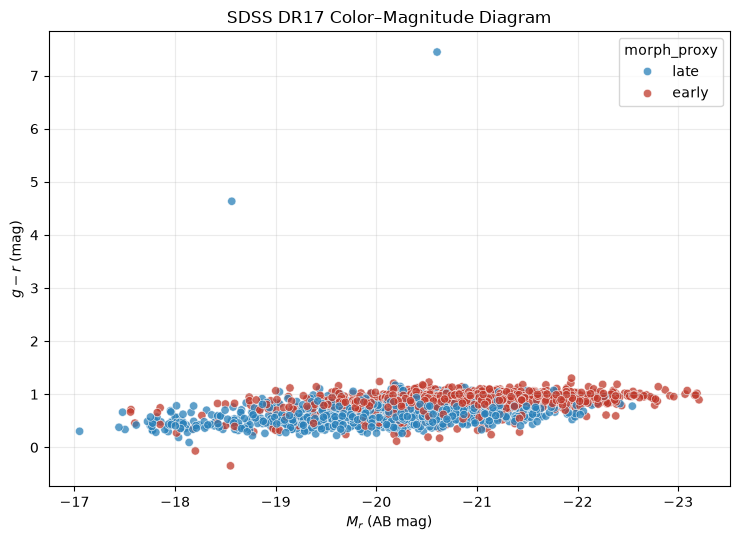

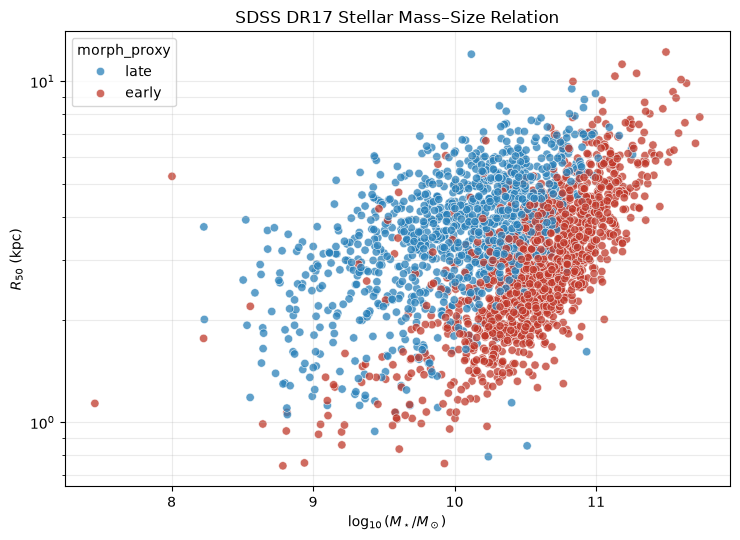

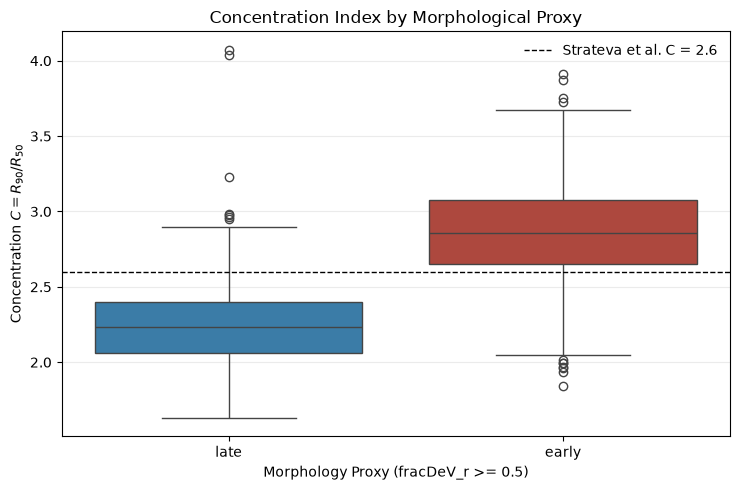

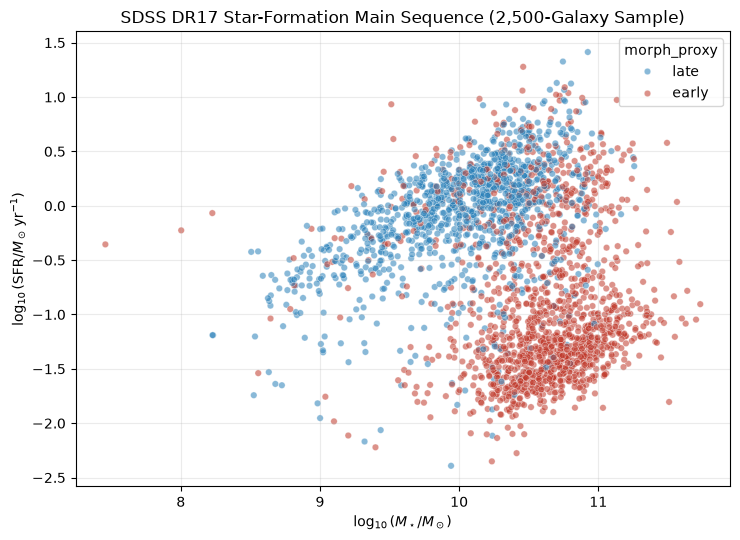

Saved figures to: C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\outputs\figures


In [4]:
config.ensure_directories()

plot_color_magnitude(sample_df, config.figures_dir / "color_magnitude_diagram.png")
plot_mass_size_relation(sample_df, config.figures_dir / "mass_size_relation.png")
plot_concentration_morphology(sample_df, config.figures_dir / "concentration_morphology.png")

# Bonus plot: Star-Formation Main Sequence (log_sfr vs log_stellar_mass)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(
    data=sample_df,
    x="log_stellar_mass",
    y="log_sfr",
    hue="morph_proxy",
    palette={"early": "#c0392b", "late": "#2980b9"},
    alpha=0.55,
    s=22,
    ax=ax,
)
ax.set_xlabel(r"$\log_{10}(M_\star / M_\odot)$")
ax.set_ylabel(r"$\log_{10}(\mathrm{SFR} / M_\odot\,\mathrm{yr}^{-1})$")
ax.set_title("SDSS DR17 Star-Formation Main Sequence (2,500-Galaxy Sample)")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(config.figures_dir / "star_formation_main_sequence.png", dpi=150)

plt.show()
print("Saved figures to:", config.figures_dir)

---
## Step 5: Quantiles & Data Distribution Check

Before moving to Phase 2 (downloading galaxy images for these `objID`s), let's inspect the percentiles (`min`, `25%`, `median`, `75%`, `max`) of every key physical quantity to confirm there are no remaining outliers or corrupted values.

In [5]:
key_cols = [
    "redshift",
    "abs_mag_r",
    "color_gr",
    "color_ug",
    "log_stellar_mass",
    "log_sfr",
    "re_kpc",
    "concentration",
    "frac_dev_r",
]
sample_df[key_cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3)

,redshift,abs_mag_r,color_gr,color_ug,log_stellar_mass,log_sfr,re_kpc,concentration,frac_dev_r
count,2489.000,2489.000,2489.000,2489.000,2489.000,2489.000,2489.000,2489.000,2489.000
mean,0.069,-20.561,0.779,1.615,10.339,-0.534,3.487,2.584,0.549
std,0.021,0.943,0.255,0.390,0.553,0.750,1.519,0.411,0.400
min,0.020,-23.207,-0.348,-4.646,7.458,-2.392,0.745,1.632,0.000
5%,0.029,-21.987,0.407,1.045,9.271,-1.673,1.476,1.956,0.000
25%,0.053,-21.173,0.621,1.312,10.051,-1.232,2.374,2.252,0.121
50%,0.074,-20.633,0.827,1.662,10.415,-0.428,3.221,2.575,0.605
75%,0.085,-20.080,0.933,1.908,10.729,0.107,4.349,2.896,0.998
95%,0.095,-18.784,1.035,2.088,11.094,0.550,6.265,3.258,1.000
max,0.100,-17.051,7.444,6.841,11.732,1.414,12.186,4.073,1.000
